# FI-SEL و PFI-SEL روی Edge-IIoTset

این نوت‌بوک مراحل اصلی بازپیاده‌سازی را نشان می‌دهد و فقط از ماژول‌های `src/` استفاده می‌کند. همه‌ی آزمایش‌ها با `run_experiments.py` اجرا می‌شوند و این نوت‌بوک فقط یک نمونه با seed=42 را نشان می‌دهد.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import config, data, evaluate, models, selection

SEED = config.MAIN_SEED
K = 8

## ۱. بارگذاری داده و تعداد کلاس‌ها

In [2]:
X, y = data.load_dataset()
print(X.shape)
counts = y.value_counts().reindex(config.CLASS_ORDER).rename("rows").to_frame()
counts["paper_table3"] = [config.EXPECTED_CLASS_COUNTS[c] for c in counts.index]
counts

(157800, 42)


,rows,paper_table3
class,,
Normal,24301,24301
DDoS,49396,49396
Information gathering,21148,21148
MITM,1214,1214
Injection,30632,30632
Malware,31109,31109


In [3]:
s = data.split(X, y, SEED)
{"fit": len(s.y_fit), "val": len(s.y_val), "train": len(s.y_train), "test": len(s.y_test)}

{'fit': 100992, 'val': 25248, 'train': 126240, 'test': 31560}

## ۲. رتبه‌بندی FI و PFI

FI روی `X_fit` محاسبه می‌شود. PFI با ExtraTrees روی `X_fit` و جابه‌جایی روی `X_val` محاسبه می‌شود. این مرحله حدود یک تا دو دقیقه طول می‌کشد.

In [4]:
fi = selection.rank_fi(s.X_fit, s.y_fit, SEED)
pfi = selection.rank_pfi(s.X_fit, s.y_fit, s.X_val, s.y_val, SEED)
top = pd.DataFrame({"FI": fi["feature"].head(K).to_numpy(), "PFI": pfi["feature"].head(K).to_numpy()},
                   index=range(1, K + 1))
top["FI_in_paper_top8"] = top["FI"].isin(config.PAPER_TOP8)
top

,FI,PFI,FI_in_paper_top8
1,tcp.dstport,tcp.dstport,True
2,tcp.ack,tcp.ack,True
3,tcp.seq,icmp.seq_le,True
4,tcp.ack_raw,tcp.seq,True
5,tcp.flags,tcp.flags,True
6,tcp.checksum,tcp.len,True
7,tcp.len,tcp.connection.rst,True
8,tcp.flags.ack,udp.stream,True


## ۳. آموزش SEL با k=8

مدل‌ها روی کل داده‌ی آموزش (`X_train`) آموزش می‌بینند و روی داده‌ی آزمون سنجیده می‌شوند.

In [5]:
rows = {}
for name, ranking in (("FI-SEL", fi), ("PFI-SEL", pfi)):
    idx = ranking["column_index"].iloc[:K].tolist()
    pipe = models.make_pipeline(models.make_sel(SEED), idx)
    rows[name] = evaluate.fit_and_evaluate(pipe, s.X_train, s.y_train, s.X_test, s.y_test)

## ۴. معیارها

In [6]:
cols = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "train_time_s", "predict_time_s", "size_bytes"]
pd.DataFrame({n: {c: r[c] for c in cols} for n, r in rows.items()}).T.round(2)

,accuracy,precision_macro,recall_macro,f1_macro,train_time_s,predict_time_s,size_bytes
FI-SEL,87.53,90.80,78.35,81.58,9.71,0.01,2186184.0
PFI-SEL,89.05,90.96,79.71,82.26,4.92,0.01,1538376.0


In [7]:
per_class = pd.concat(
    {n: pd.DataFrame(r["per_class"]).T[["precision", "recall", "f1", "support"]] for n, r in rows.items()},
    axis=1)
per_class.round(2)

FI-SEL                         PFI-SEL                \
                      precision recall     f1 support precision recall     f1   
Normal                    94.50  93.66  94.08  4860.0     94.86  93.70  94.28   
DDoS                      82.89  91.72  87.08  9879.0     88.84  95.30  91.96   
Information gathering     93.24  85.46  89.18  4230.0     82.94  93.55  87.92   
MITM                     100.00  32.10  48.60   243.0    100.00  32.10  48.60   
Injection                 84.65  83.35  83.99  6126.0     85.28  83.89  84.58   
Malware                   89.51  83.78  86.55  6222.0     93.85  79.73  86.22   

                               
                      support  
Normal                 4860.0  
DDoS                   9879.0  
Information gathering  4230.0  
MITM                    243.0  
Injection              6126.0  
Malware                6222.0

## ۵. نمودارهای ذخیره‌شده

این نمودارها با `run_experiments.py figures` ساخته شده‌اند و میانگین پنج seed را نشان می‌دهند.

importance_ranking_fi_pfi.png


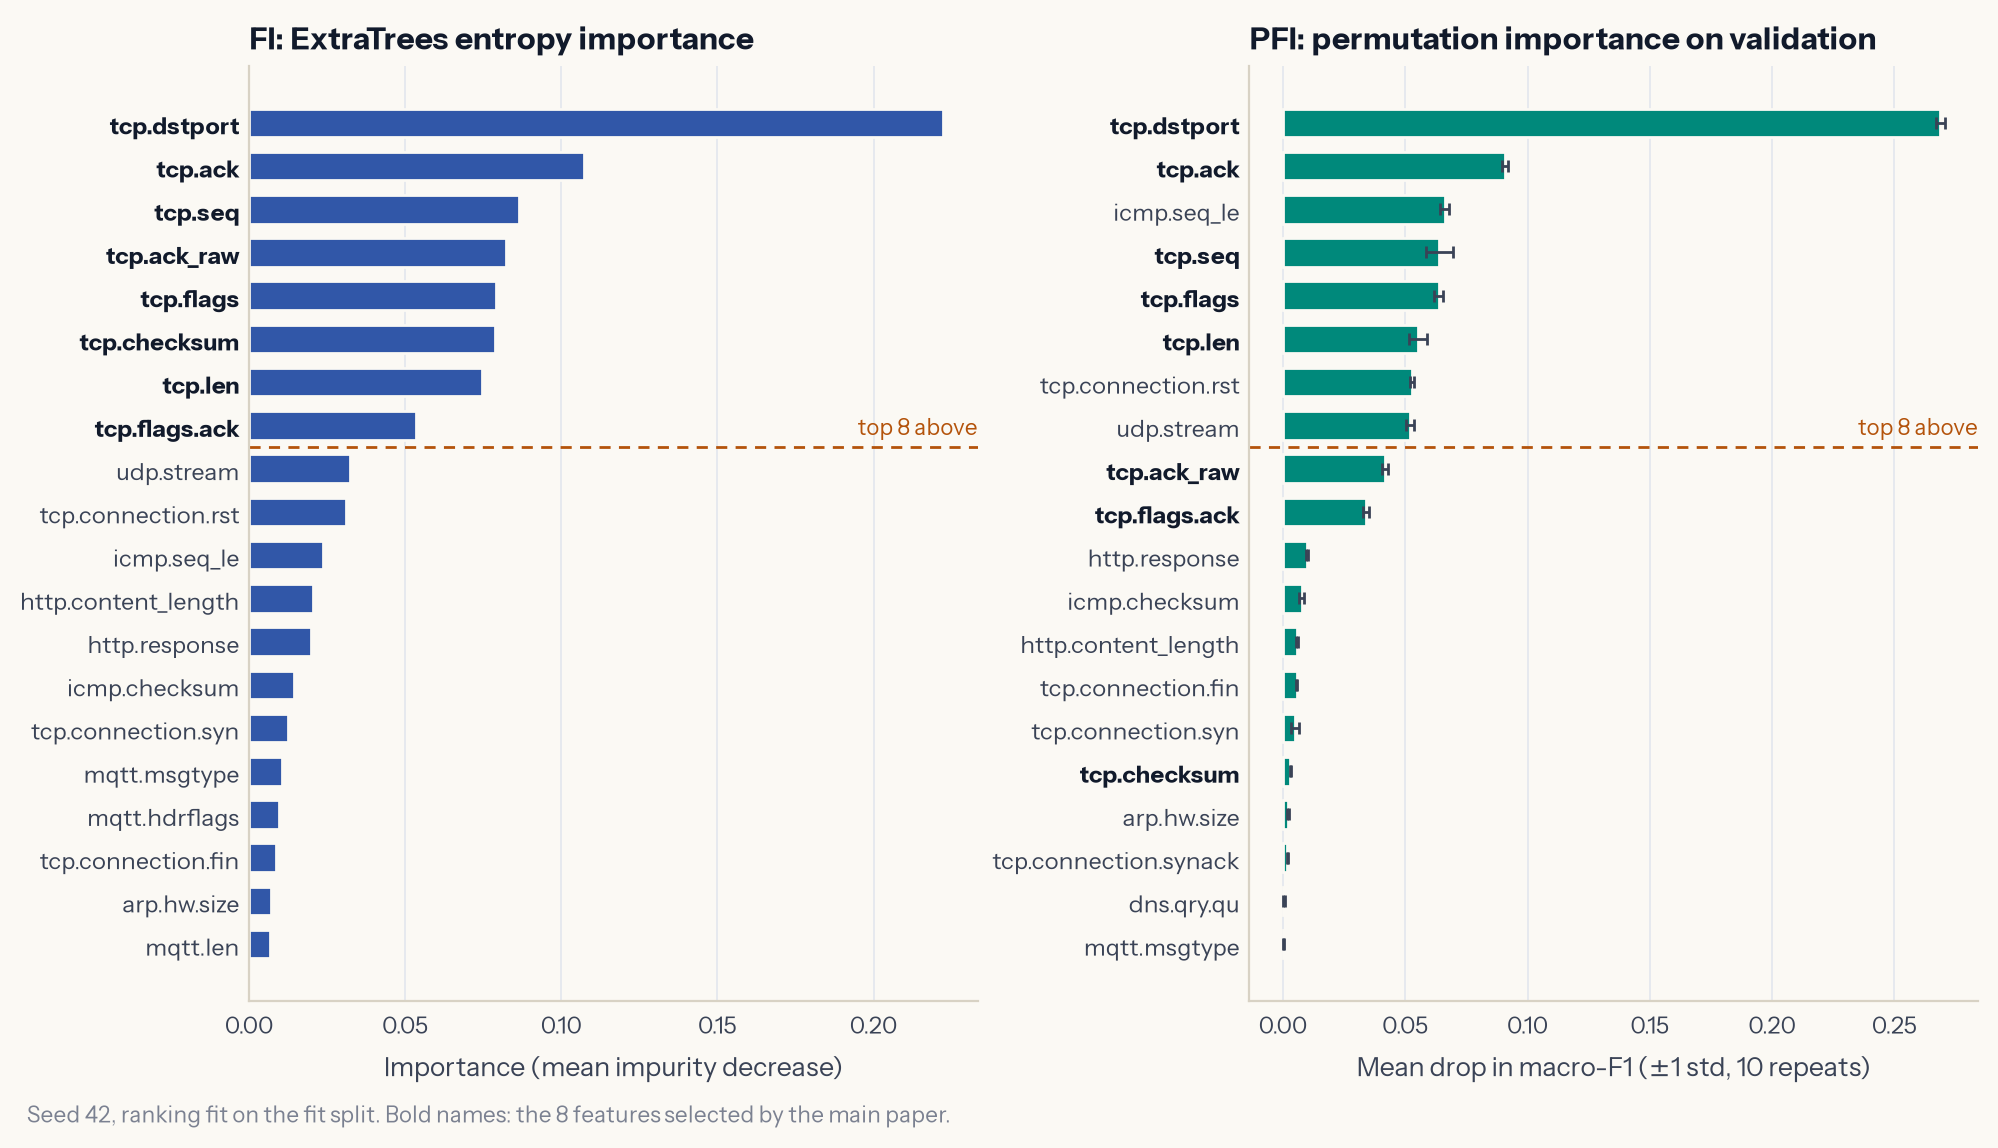

f1_macro_vs_k.png


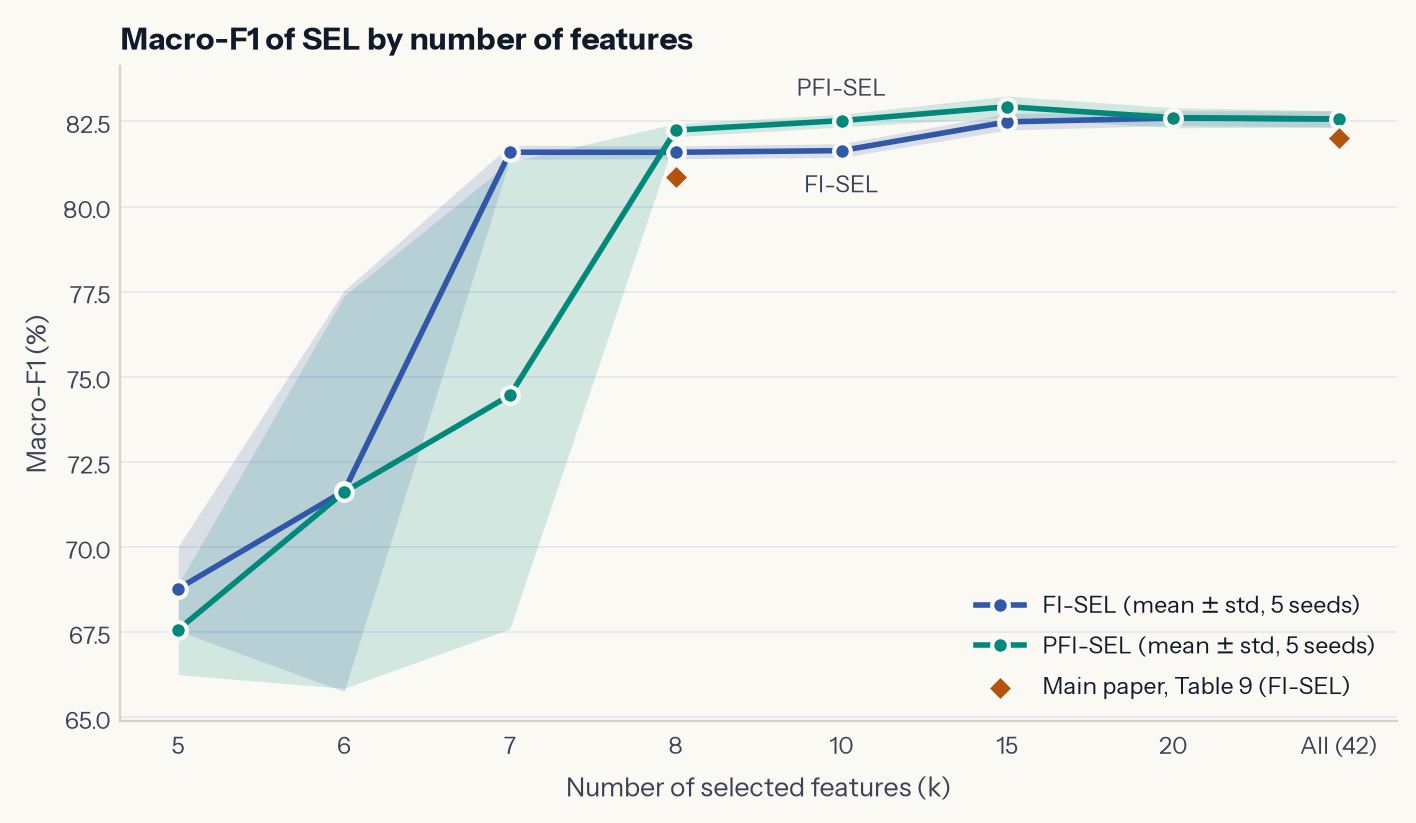

methods_vs_k.png


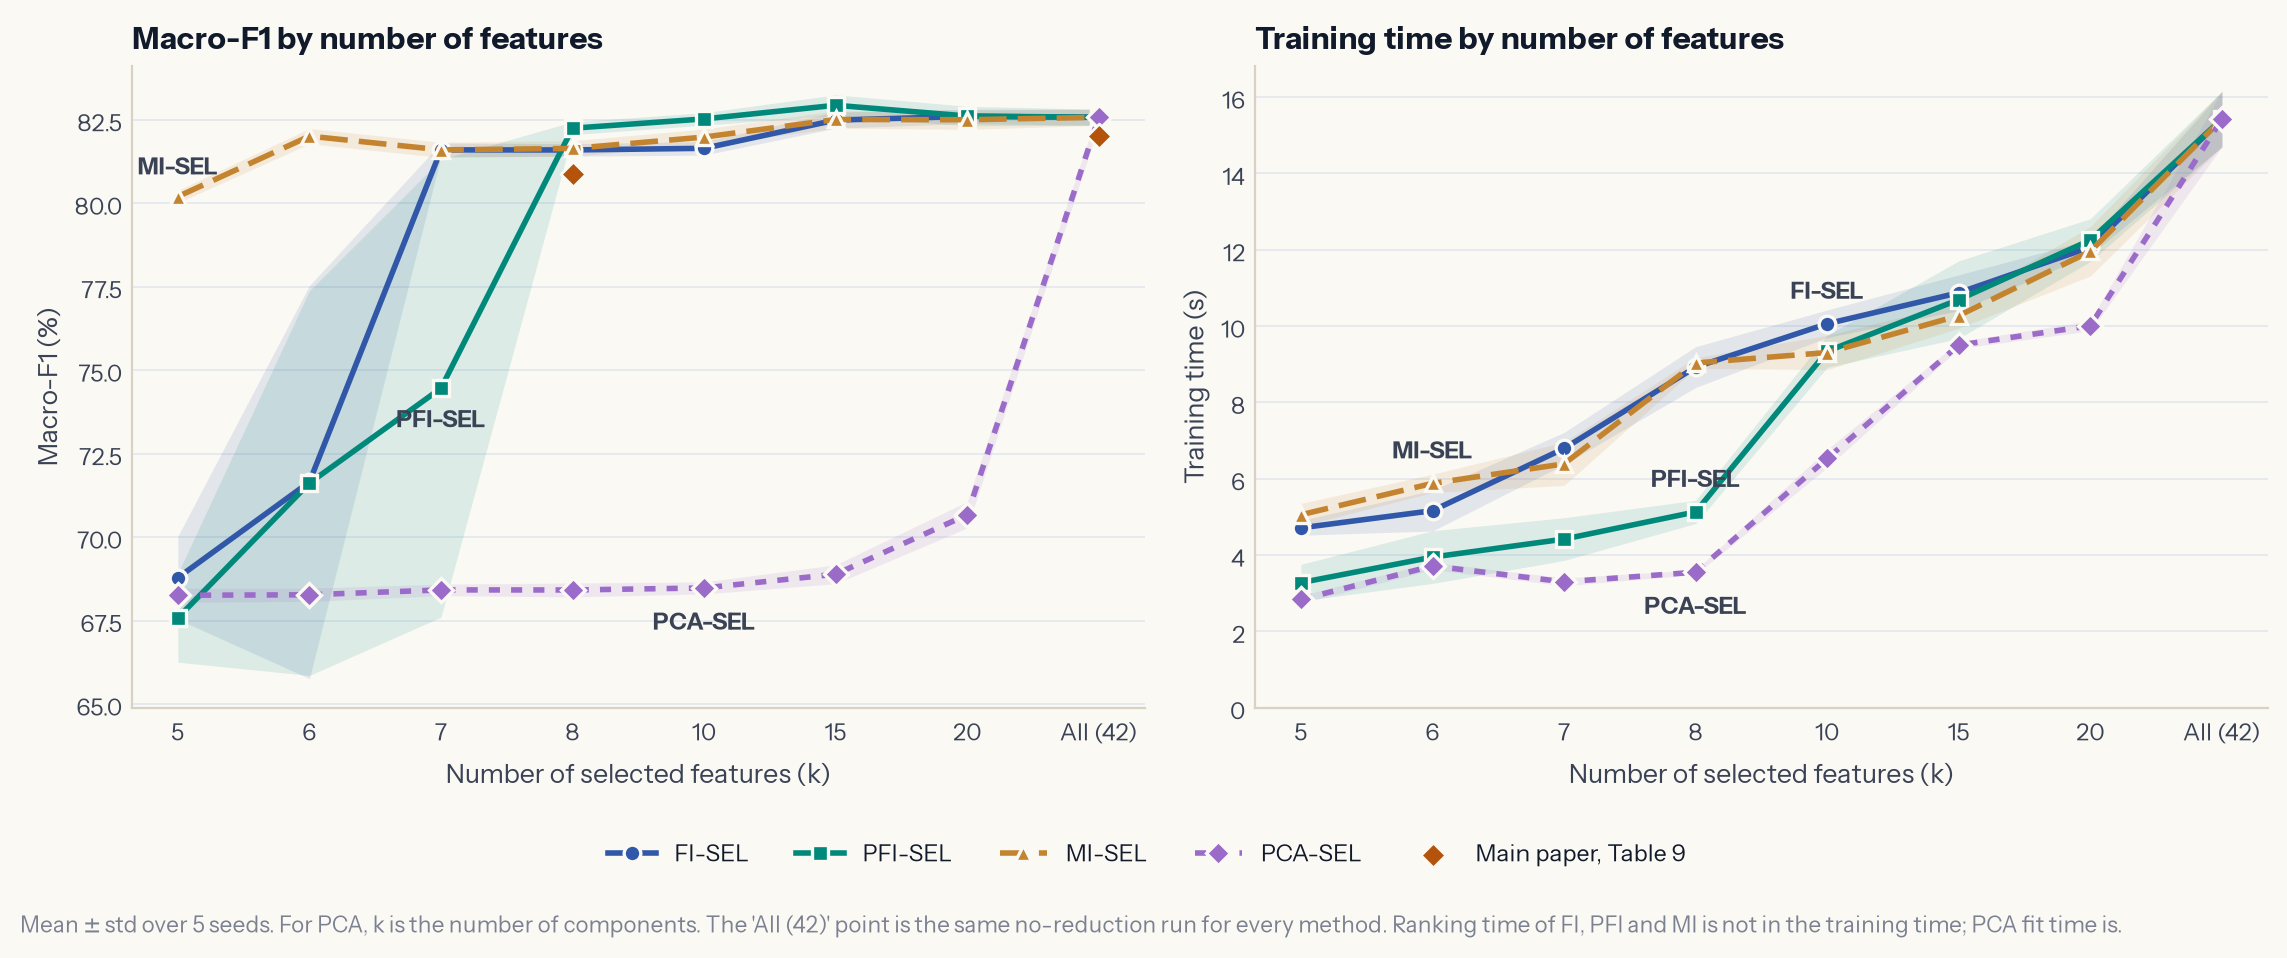

per_class_recall_k8.png


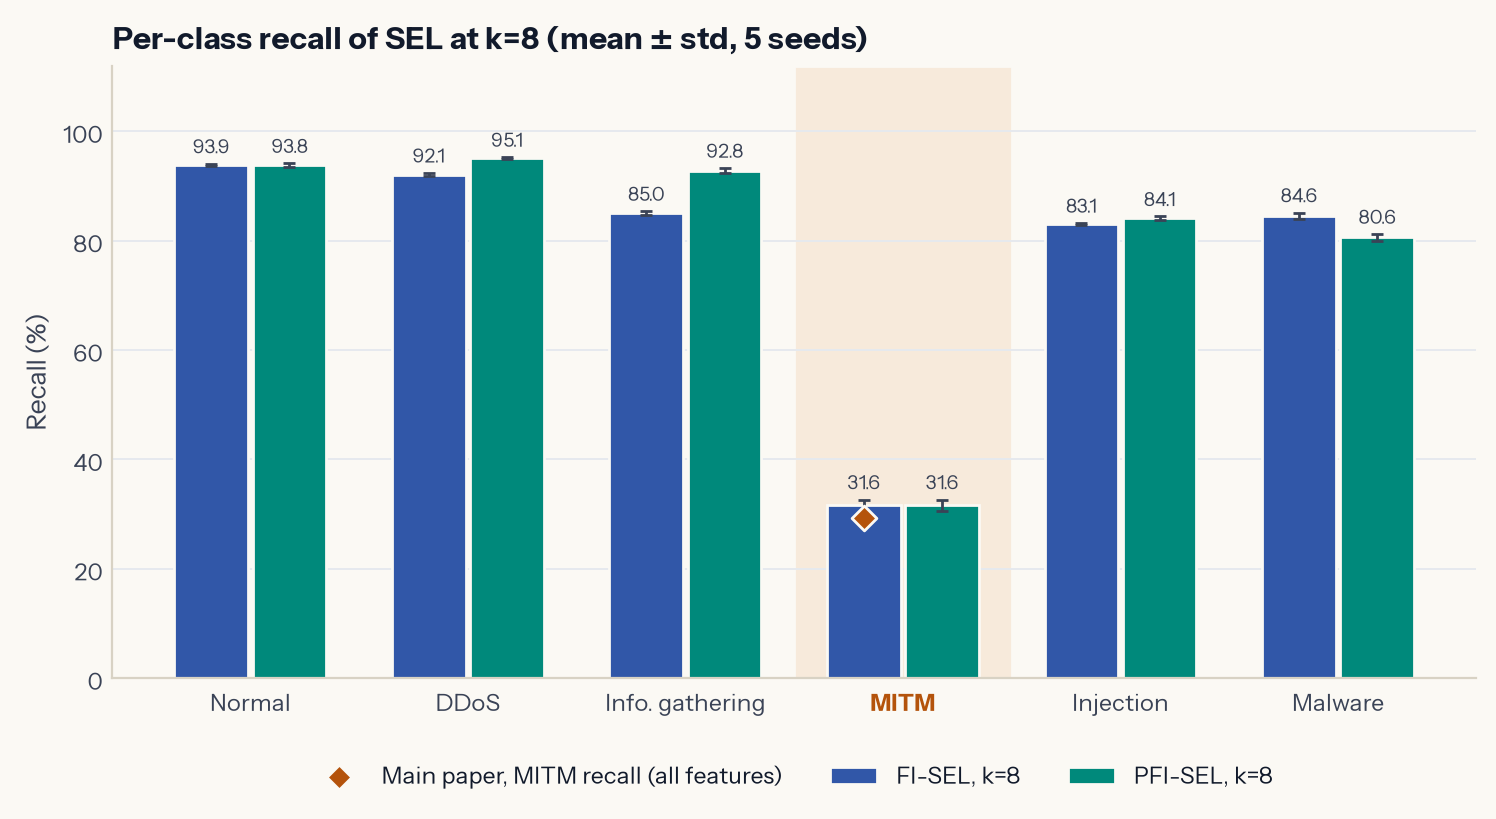

class_weight_k8.png


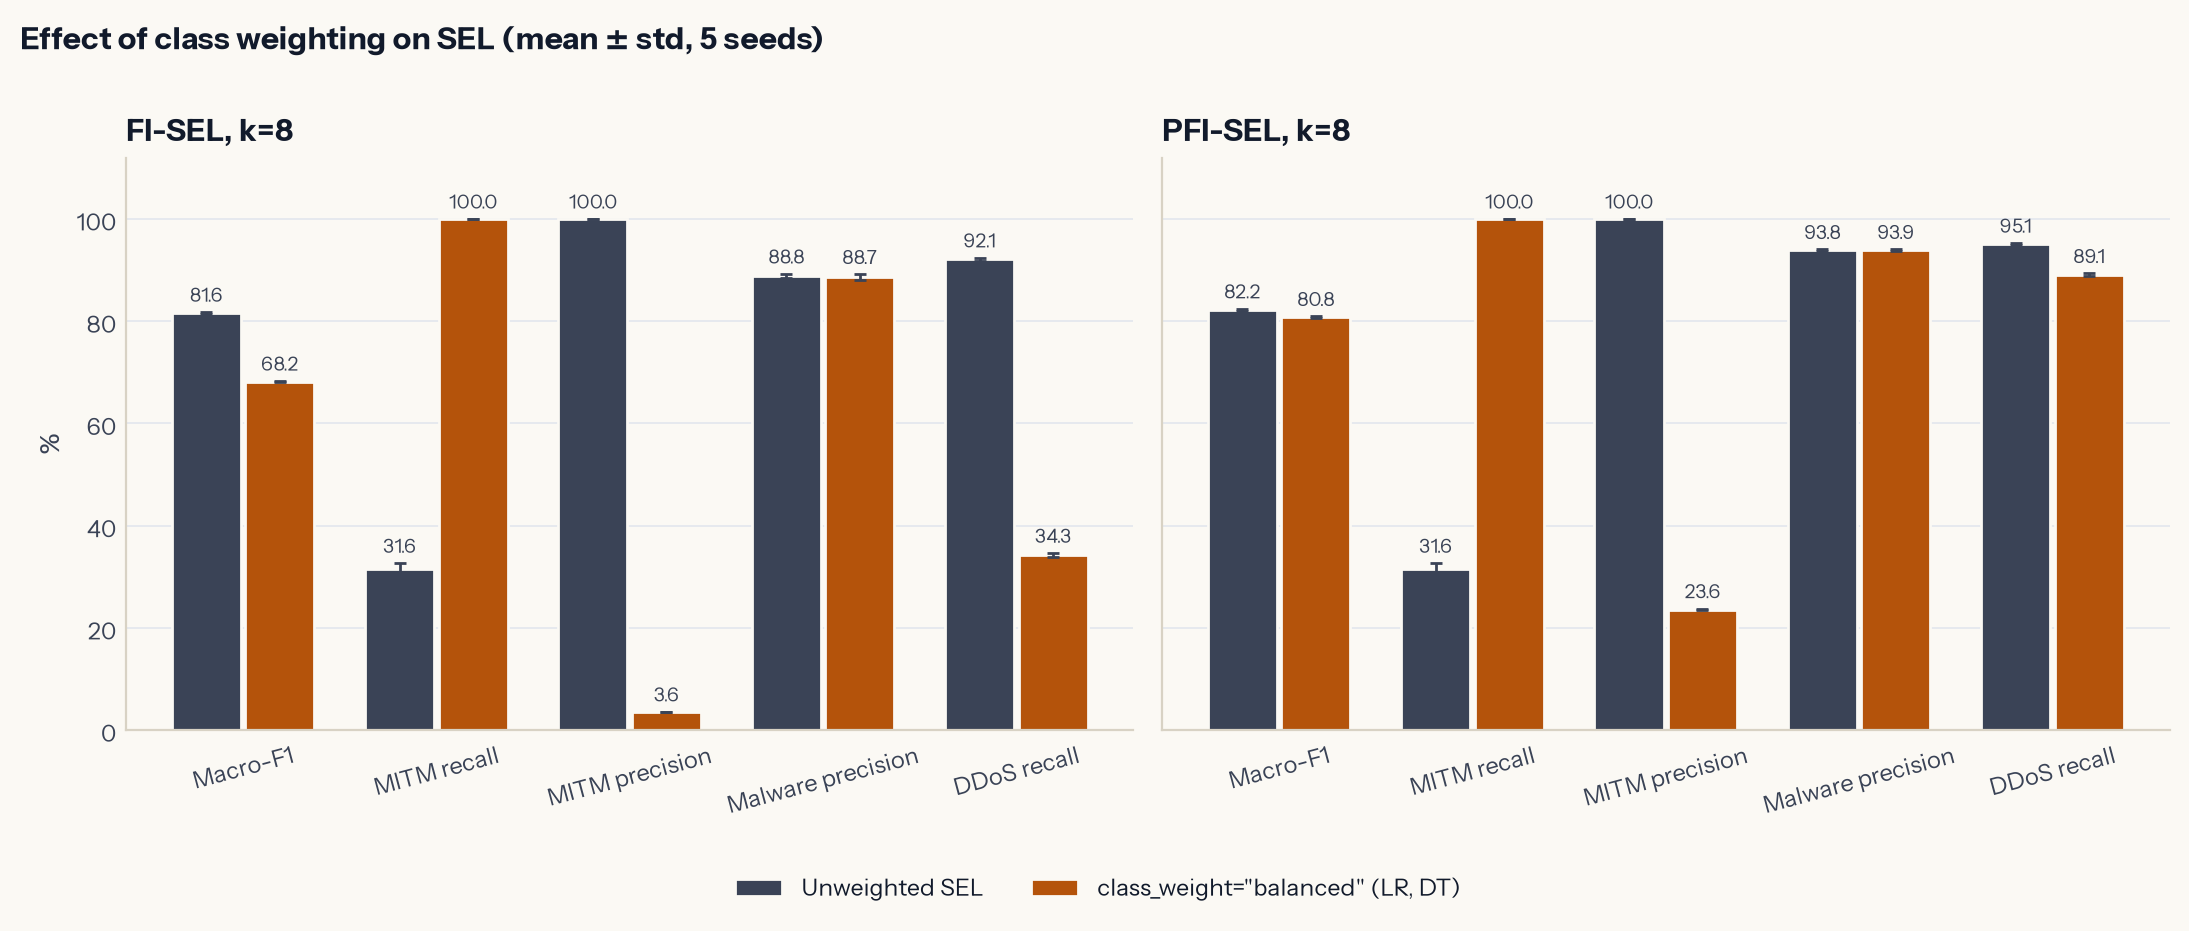

leaky_vs_clean.png


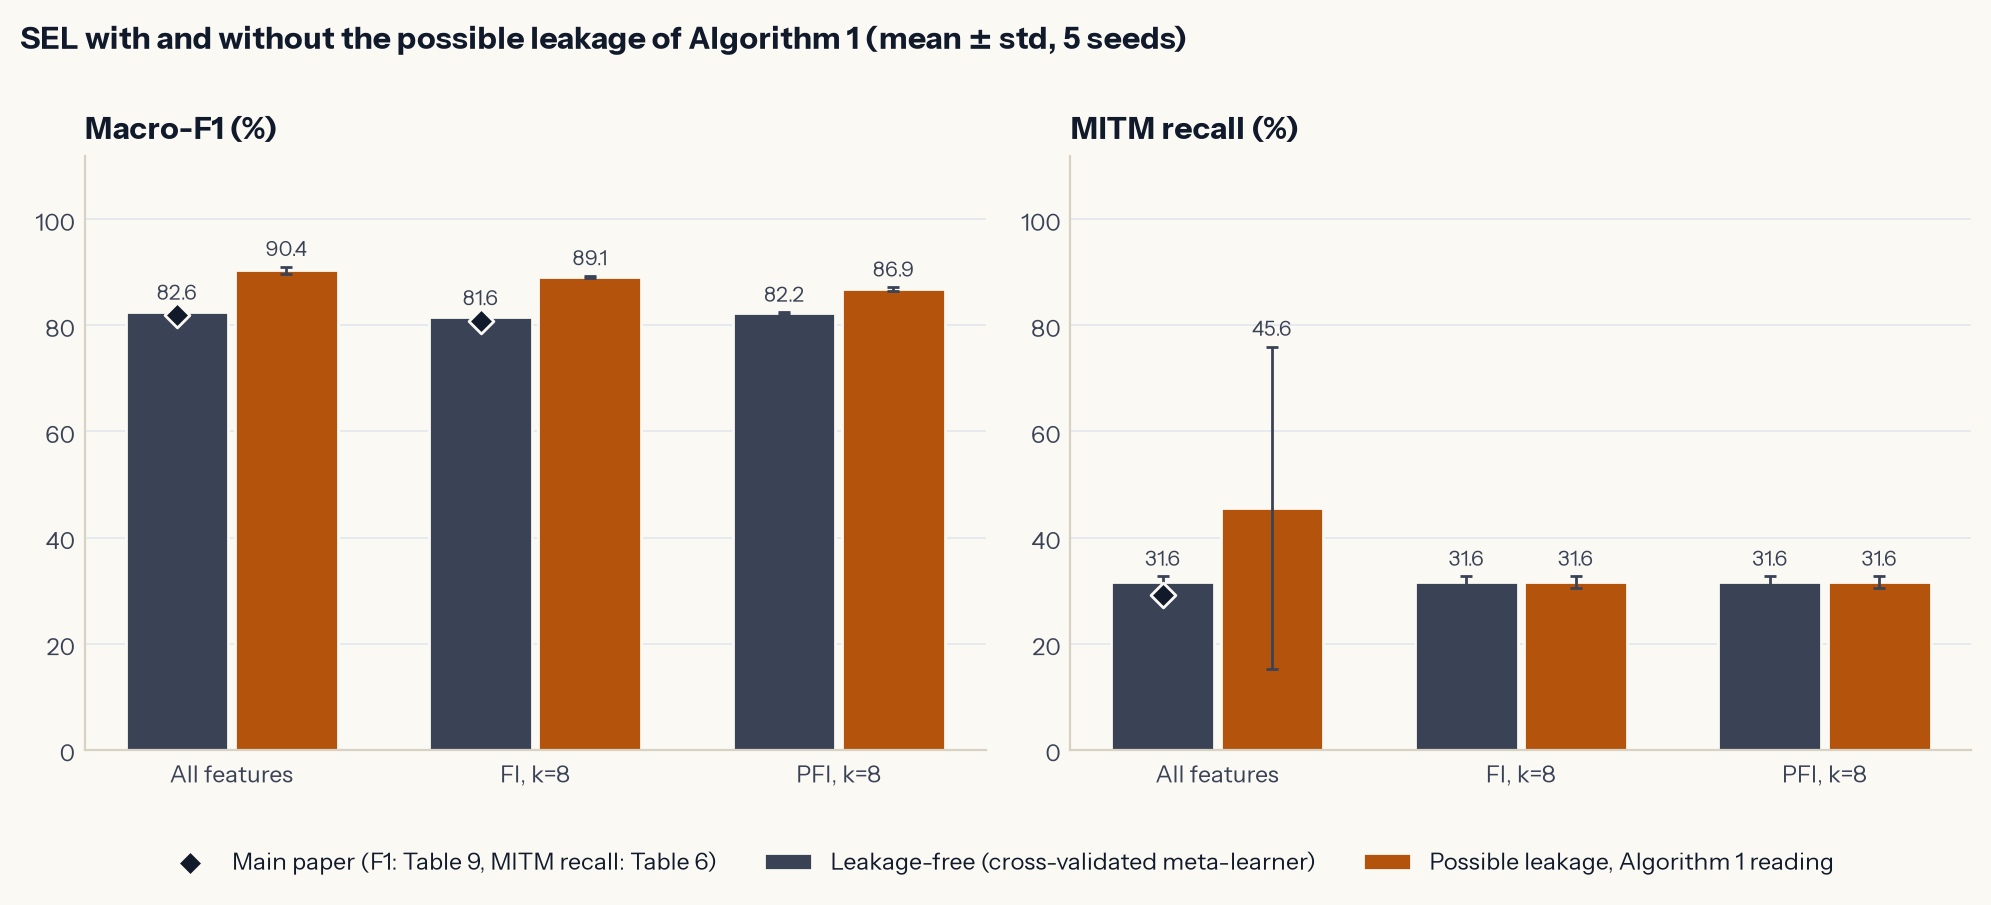

In [8]:
FIG = ROOT / "results" / "figures"
for name in ["importance_ranking_fi_pfi.png", "f1_macro_vs_k.png", "methods_vs_k.png",
             "per_class_recall_k8.png", "class_weight_k8.png", "leaky_vs_clean.png"]:
    path = FIG / name
    if path.exists():
        print(name)
        display(Image(filename=str(path), width=820))